### Home vs. Away Efficiency

This notebook compares Cristiano Ronaldo's scoring rate in home and away games by venue, competition, and club.

In [ ]:
from pathlib import Path
import json

import pandas as pd
import matplotlib.pyplot as plt

# This notebook is saved in data/notebooks.
MATCH_DIR = Path("../matches")
CHART_DIR = Path("../../public/images/articles")
CHART_DIR.mkdir(parents=True, exist_ok=True)

print(f"Reading match files from: {MATCH_DIR.resolve()}")
print(f"Saving charts to: {CHART_DIR.resolve()}")

records = []

for file_path in sorted(MATCH_DIR.glob("*.json")):
    with file_path.open("r", encoding="utf-8") as file:
        content = json.load(file)

    if isinstance(content, list):
        for match in content:
            if isinstance(match, dict):
                match = match.copy()
                match.setdefault("_source_file", file_path.name)
                records.append(match)
    elif isinstance(content, dict):
        # Some files may wrap matches in a top-level key.
        if isinstance(content.get("matches"), list):
            for match in content["matches"]:
                if isinstance(match, dict):
                    match = match.copy()
                    match.setdefault("_source_file", file_path.name)
                    records.append(match)
        else:
            match = content.copy()
            match.setdefault("_source_file", file_path.name)
            records.append(match)

df = pd.DataFrame(records)
print(f"Loaded {len(df):,} match records from {len(list(MATCH_DIR.glob('*.json'))):,} JSON files.")
display(df.head())

# Check that the fields needed for the analysis exist.
required_columns = ["goals", "minutesPlayed", "venue", "competition", "team"]
missing_columns = [column for column in required_columns if column not in df.columns]
if missing_columns:
    raise ValueError(
        "These expected columns are missing: " + ", ".join(missing_columns) +
        ". Inspect the source JSON schema and update the column names in this cell."
    )

print("Venue values found:")
display(df["venue"].value_counts(dropna=False).to_frame("matches"))

print("Missing values in key fields:")
display(df[required_columns].isna().sum().to_frame("missing rows"))

analysis = df.copy()

def normalize_venue(value):
    if pd.isna(value):
        return pd.NA
    value = str(value).strip().lower().replace("_", " ").replace("-", " ")
    mapping = {
        "home": "Home",
        "h": "Home",
        "away": "Away",
        "a": "Away",
        "neutral": "Neutral",
        "neutral venue": "Neutral",
        "n": "Neutral",
    }
    return mapping.get(value, pd.NA)

analysis["venue_clean"] = analysis["venue"].apply(normalize_venue)
analysis["goals_num"] = pd.to_numeric(analysis["goals"], errors="coerce")
analysis["minutes_num"] = pd.to_numeric(analysis["minutesPlayed"], errors="coerce")
analysis["competition_clean"] = analysis["competition"].astype("string").str.strip()
analysis["club_clean"] = analysis["team"].astype("string").str.strip()

# Missing goal counts are not silently treated as zero; inspect them first.
print("Rows with missing/unrecognized venue:", analysis["venue_clean"].isna().sum())
print("Rows with missing/non-numeric goal count:", analysis["goals_num"].isna().sum())
print("Rows with missing/non-numeric minutes:", analysis["minutes_num"].isna().sum())
print("Rows with zero or negative minutes:", (analysis["minutes_num"] <= 0).sum())

display(analysis[["date", "team", "competition", "venue", "venue_clean", "goals", "minutesPlayed"]].head(10))

VENUE_ORDER = ["Home", "Away", "Neutral"]

def summarize_groups(data, group_columns):
    """Summarize raw goals and calculate goals per 90 using only rows with valid minutes."""
    valid_goals = data.dropna(subset=["goals_num"]).copy()
    valid_goals["goals_with_minutes"] = valid_goals["goals_num"].where(valid_goals["minutes_num"] > 0)
    valid_goals["valid_minutes"] = valid_goals["minutes_num"].where(valid_goals["minutes_num"] > 0)

    summary = (
        valid_goals.groupby(group_columns, dropna=False)
        .agg(
            goals=("goals_num", "sum"),
            goals_with_minutes=("goals_with_minutes", "sum"),
            minutes=("valid_minutes", lambda values: values.sum(min_count=1)),
            matches_with_goal_data=("goals_num", "count"),
        )
        .reset_index()
    )
    summary["goals_per_90"] = summary["goals_with_minutes"] / summary["minutes"] * 90
    summary.loc[summary["minutes"].isna() | (summary["minutes"] <= 0), "goals_per_90"] = float("nan")
    return summary

venue_data = analysis[analysis["venue_clean"].isin(VENUE_ORDER)].copy()
venue_summary = summarize_groups(venue_data, ["venue_clean"])
venue_summary["venue_clean"] = pd.Categorical(venue_summary["venue_clean"], categories=VENUE_ORDER, ordered=True)
venue_summary = venue_summary.sort_values("venue_clean")
display(venue_summary)

Reading match files from: C:\Users\soham\OneDrive\Desktop\ronaldo-archive\ronaldo-archive\data\matches
Saving charts to: C:\Users\soham\OneDrive\Desktop\ronaldo-archive\ronaldo-archive\public\images\articles
Loaded 1,341 match records from 25 JSON files.


,id,date,season,team,competition,stage,leg,opponent,venue,result,...,goals,assists,yellowCard,redCard,hasMatchComp,matchCompUrl,hasFullMatch,fullMatchUrl,_source_file,stats
0,2002-08-14,2002-08-14,2002/03,Sporting CP,UEFA Champions League Qualifying,Play-off,1st Leg,Inter Milan,Home,D,...,0,0,None,None,True,https://vimeo.com/312097381,True,https://footballia.net/matches/sporting-cp-fc-...,2002-03.json,NaN
1,2002-09-19,2002-09-19,2002/03,Sporting CP,UEFA Cup,Round of 96,1st Leg,Partizan Belgrade,Home,L,...,0,0,None,None,True,https://www.youtube.com/watch?v=BD-JrESn88Q,True,https://footballia.net/matches/sporting-cp-fk-...,2002-03.json,NaN
2,2002-09-29,2002-09-29,2002/03,Sporting CP,Primeira Liga,League,NaN,Sporting Braga,Away,L,...,0,0,None,None,False,,False,,2002-03.json,NaN
3,2002-10-03,2002-10-03,2002/03,Sporting CP,UEFA Cup,Round of 96,2nd Leg,Partizan Belgrade,Away,D,...,0,0,None,None,True,https://vimeo.com/224993953,True,https://www.youtube.com/watch?v=CpHapaPu0aw,2002-03.json,NaN
4,2002-10-07,2002-10-07,2002/03,Sporting CP,Primeira Liga,League,NaN,Moreirense,Home,W,...,2,0,None,None,True,https://youtube.com/watch?v=nVsicMbOniw,False,,2002-03.json,NaN


Venue values found:


,matches
venue,
Home,652
Away,583
Neutral,106


Missing values in key fields:


,missing rows
goals,0
minutesPlayed,0
venue,0
competition,0
team,0


Rows with missing/unrecognized venue: 0
Rows with missing/non-numeric goal count: 0
Rows with missing/non-numeric minutes: 0
Rows with zero or negative minutes: 0


,date,team,competition,venue,venue_clean,goals,minutesPlayed
0,2002-08-14,Sporting CP,UEFA Champions League Qualifying,Home,Home,0,32
1,2002-09-19,Sporting CP,UEFA Cup,Home,Home,0,45
2,2002-09-29,Sporting CP,Primeira Liga,Away,Away,0,21
3,2002-10-03,Sporting CP,UEFA Cup,Away,Away,0,74
4,2002-10-07,Sporting CP,Primeira Liga,Home,Home,2,90
5,2002-10-20,Sporting CP,Primeira Liga,Home,Home,0,76
6,2002-10-26,Sporting CP,Primeira Liga,Away,Away,1,8
7,2002-11-02,Sporting CP,Primeira Liga,Home,Home,0,90
8,2002-11-08,Sporting CP,Primeira Liga,Away,Away,0,89
9,2002-11-15,Sporting CP,Primeira Liga,Home,Home,0,74


,venue_clean,goals,goals_with_minutes,minutes,matches_with_goal_data,goals_per_90
1,Home,529,529,53349,652,0.892425
0,Away,395,395,47143,583,0.754089
2,Neutral,57,57,9215,106,0.556701


Visualization 1: Goals by venue

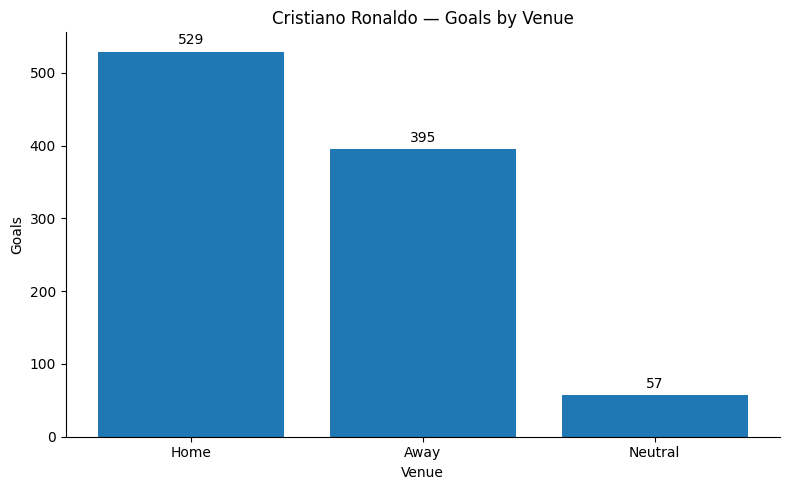

In [ ]:
plot_data = venue_summary.dropna(subset=["goals"]).copy()
plot_data["venue_clean"] = plot_data["venue_clean"].astype(str)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(plot_data["venue_clean"], plot_data["goals"])
ax.set_title("Cristiano Ronaldo — Goals by Venue")
ax.set_xlabel("Venue")
ax.set_ylabel("Goals")
ax.bar_label(bars, fmt="%.0f", padding=3)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(CHART_DIR / "ronaldo-goals-by-venue.png", dpi=200, bbox_inches="tight")
plt.show()

Visualization 2: Goals per 90 minutes by venue

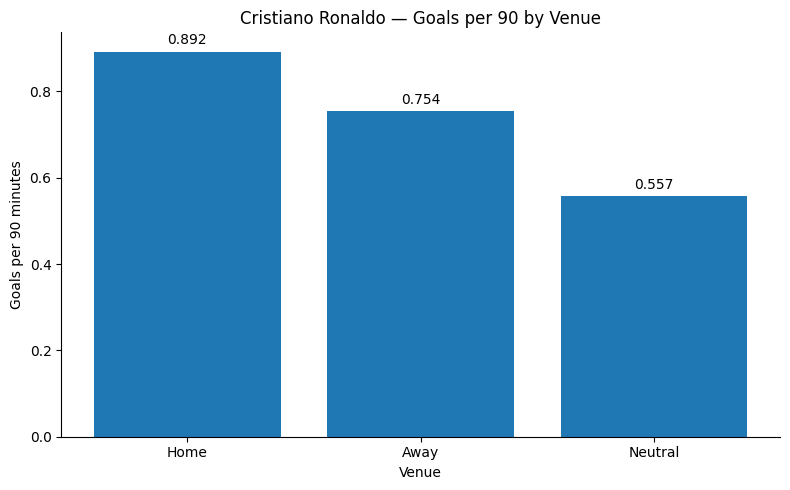

In [ ]:
rate_data = venue_summary.dropna(subset=["goals_per_90"]).copy()
rate_data["venue_clean"] = rate_data["venue_clean"].astype(str)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(rate_data["venue_clean"], rate_data["goals_per_90"])
ax.set_title("Cristiano Ronaldo — Goals per 90 by Venue")
ax.set_xlabel("Venue")
ax.set_ylabel("Goals per 90 minutes")
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(CHART_DIR / "ronaldo-goals-per-90-by-venue.png", dpi=200, bbox_inches="tight")
plt.show()

Visualization 3: Goal distribution by competition

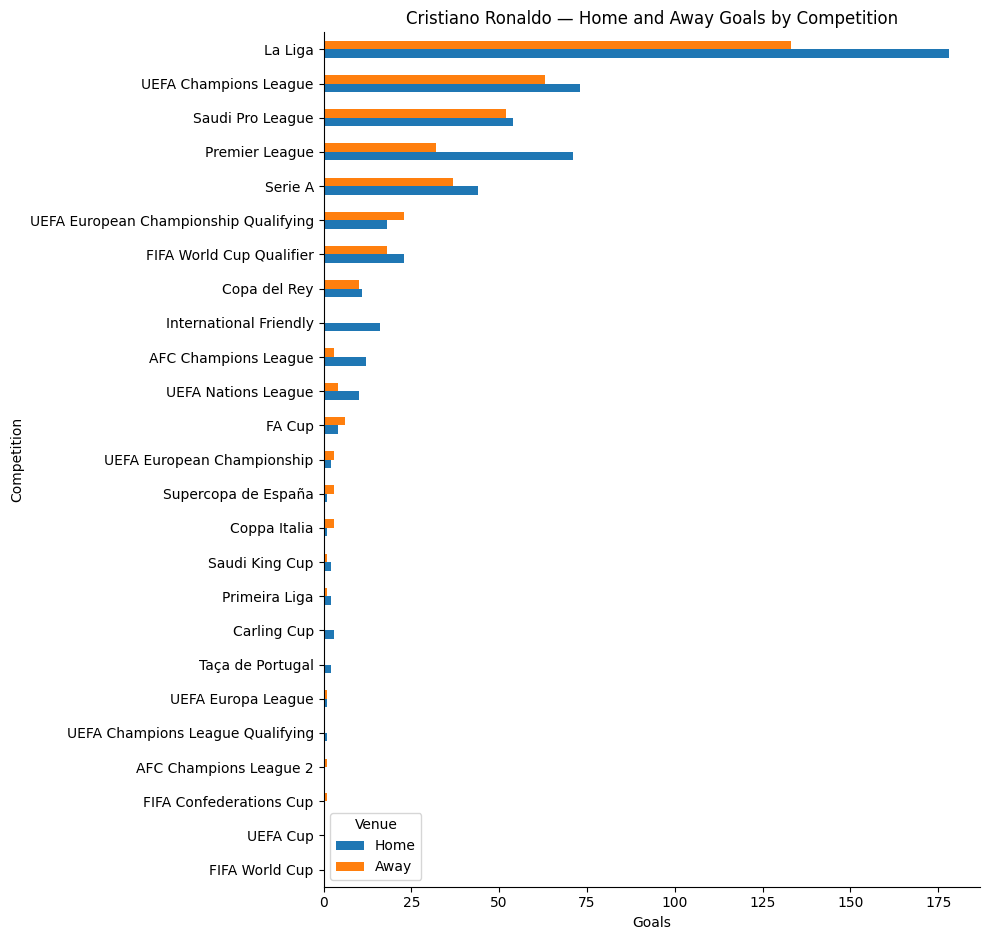

venue_clean,Away,Home,total
competition_clean,,,
La Liga,133,178,311
UEFA Champions League,63,73,136
Saudi Pro League,52,54,106
Premier League,32,71,103
Serie A,37,44,81
FIFA World Cup Qualifier,18,23,41
UEFA European Championship Qualifying,23,18,41
Copa del Rey,10,11,21
International Friendly,0,16,16


In [ ]:
home_away = analysis[analysis["venue_clean"].isin(["Home", "Away"])].copy()
competition_data = home_away.dropna(subset=["competition_clean", "goals_num"])
competition_summary = (
    competition_data.groupby(["competition_clean", "venue_clean"])["goals_num"]
    .sum()
    .unstack("venue_clean", fill_value=0)
)
for venue_name in ["Home", "Away"]:
    if venue_name not in competition_summary.columns:
        competition_summary[venue_name] = 0
competition_summary["total"] = competition_summary["Home"] + competition_summary["Away"]
competition_summary = competition_summary.sort_values("total", ascending=True)

fig_height = max(5, 0.38 * len(competition_summary))
fig, ax = plt.subplots(figsize=(10, fig_height))
competition_summary[["Home", "Away"]].plot(kind="barh", ax=ax)
ax.set_title("Cristiano Ronaldo — Home and Away Goals by Competition")
ax.set_xlabel("Goals")
ax.set_ylabel("Competition")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Venue")
fig.tight_layout()
fig.savefig(CHART_DIR / "ronaldo-goals-by-competition-home-away.png", dpi=200, bbox_inches="tight")
plt.show()

display(competition_summary.sort_values("total", ascending=False))

Visualization 4: Total goals and goals per 90 by club

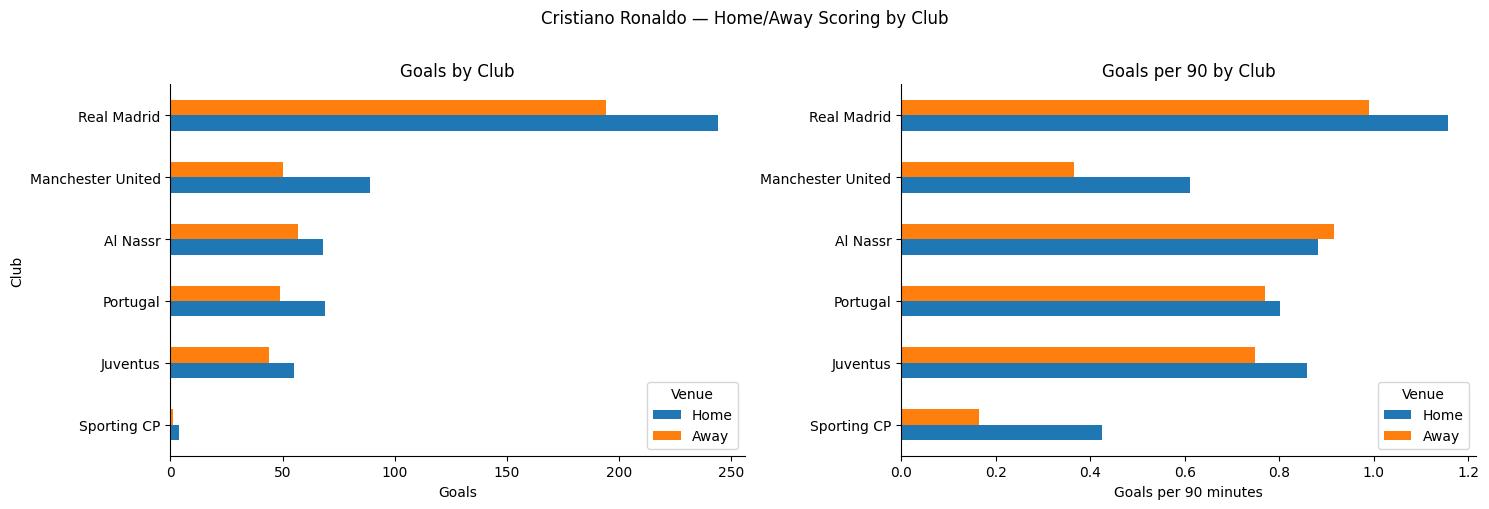

,club_clean,venue_clean,goals,goals_with_minutes,minutes,matches_with_goal_data,goals_per_90
0,Al Nassr,Away,57,57,5600,66,0.916071
1,Al Nassr,Home,68,68,6934,79,0.882607
2,Juventus,Away,44,44,5296,63,0.747734
3,Juventus,Home,55,55,5761,66,0.859226
4,Manchester United,Away,50,50,12313,164,0.365467
5,Manchester United,Home,89,89,13101,169,0.611404
6,Portugal,Away,49,49,5730,69,0.769634
7,Portugal,Home,69,69,7739,103,0.802429
8,Real Madrid,Away,194,194,17660,208,0.988675
9,Real Madrid,Home,244,244,18966,217,1.157861


In [ ]:
club_data = home_away.dropna(subset=["club_clean", "goals_num"]).copy()
club_summary = summarize_groups(club_data, ["club_clean", "venue_clean"])
club_totals = club_summary.pivot(index="club_clean", columns="venue_clean", values="goals").fillna(0)
club_rates = club_summary.pivot(index="club_clean", columns="venue_clean", values="goals_per_90")

# Order clubs by combined home-and-away goal totals.
club_order = club_totals.sum(axis=1).sort_values(ascending=True).index
club_totals = club_totals.reindex(club_order)
club_rates = club_rates.reindex(club_order)

fig_height = max(5, 0.5 * len(club_order))
fig, axes = plt.subplots(1, 2, figsize=(15, fig_height))
club_totals[[c for c in ["Home", "Away"] if c in club_totals.columns]].plot(kind="barh", ax=axes[0])
axes[0].set_title("Goals by Club")
axes[0].set_xlabel("Goals")
axes[0].set_ylabel("Club")
axes[0].spines[["top", "right"]].set_visible(False)
axes[0].legend(title="Venue")

club_rates[[c for c in ["Home", "Away"] if c in club_rates.columns]].plot(kind="barh", ax=axes[1])
axes[1].set_title("Goals per 90 by Club")
axes[1].set_xlabel("Goals per 90 minutes")
axes[1].set_ylabel("")
axes[1].spines[["top", "right"]].set_visible(False)
axes[1].legend(title="Venue")
fig.suptitle("Cristiano Ronaldo — Home/Away Scoring by Club", y=1.01)
fig.tight_layout()
fig.savefig(CHART_DIR / "ronaldo-home-away-goals-by-club.png", dpi=200, bbox_inches="tight")
plt.show()

display(club_summary.sort_values(["club_clean", "venue_clean"]))